# **Project 11: Handwritten Digit Recognition Using CNN**

**Name:** Prakruthi BR

**Reg No:** 2411021240038


**Subject:** Deep Learning




## Objective

To implement a Convolutional Neural Network (CNN) for recognizing handwritten numerical digits using the MNIST dataset and measure its performance using classification accuracy, a confusion matrix, a classification report, and sample image predictions.


## Introduction

Recognizing handwritten digits is an important application of computer vision and deep learning. Since handwritten numbers can differ in size, shape, and writing style, traditional approaches may find it difficult to recognize them accurately.

The MNIST dataset provides thousands of labeled images of digits from 0 to 9. CNNs are effective for this task because they learn useful visual patterns directly from images.

This project involves preparing the dataset, designing a CNN architecture, training the network, and analyzing its predictions using different evaluation techniques.



## Task 1: Load and Preprocess the MNIST Dataset

### Theory

MNIST is a widely used dataset for handwritten digit recognition. It contains 70,000 grayscale images divided into 60,000 training images and 10,000 testing images.

Each image measures 28 × 28 pixels and belongs to one of ten classes, corresponding to the digits 0 through 9.

Before training, the images must be prepared by loading the dataset, examining sample images, scaling the pixel values, and arranging the data into the input shape expected by a CNN.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)
print("All required libraries are ready.")

TensorFlow version: 2.21.0
All required libraries are ready.


In [2]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

print("Number of training images:", train_images.shape[0])
print("Number of testing images:", test_images.shape[0])
print("Training image dimensions:", train_images.shape[1:])
print("Testing image dimensions:", test_images.shape[1:])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of training images: 60000
Number of testing images: 10000
Training image dimensions: (28, 28)
Testing image dimensions: (28, 28)



### Explanation

The dataset is imported from the Keras MNIST collection and divided into training and testing portions.

The training images and their labels are used to teach the network. The testing images are kept separate so that the final model can be assessed on data it has not seen during training.

The images are originally represented as 28 × 28 arrays of pixel values.


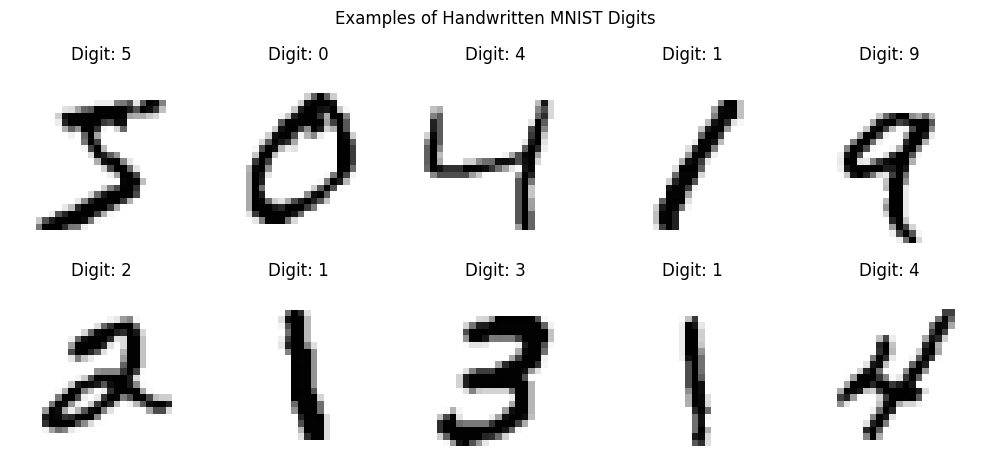

In [3]:
plt.figure(figsize=(10, 5))

for index in range(10):
    plt.subplot(2, 5, index + 1)
    plt.imshow(train_images[index], cmap="gray_r")
    plt.title("Digit: " + str(train_labels[index]))
    plt.axis("off")

plt.suptitle("Examples of Handwritten MNIST Digits")
plt.tight_layout()
plt.show()


### Explanation

A selection of training images is displayed to observe the appearance of handwritten digits. The label above each image indicates its correct numerical class.

This visualization helps us understand the input data and observe variations in how individual digits are written.


In [4]:
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

print("Lowest normalized pixel value:", train_images.min())
print("Highest normalized pixel value:", train_images.max())

Lowest normalized pixel value: 0.0
Highest normalized pixel value: 1.0



### Explanation

The original image pixels have values between 0 and 255. These values are divided by 255 to convert them into decimal values between 0 and 1.

This scaling keeps the input values within a smaller range and helps make neural network training more stable.


In [5]:
train_images = train_images.reshape(-1, 28, 28, 1)
test_images = test_images.reshape(-1, 28, 28, 1)

print("Prepared training shape:", train_images.shape)
print("Prepared testing shape:", test_images.shape)

Prepared training shape: (60000, 28, 28, 1)
Prepared testing shape: (10000, 28, 28, 1)



### Explanation

An additional channel dimension is introduced because the CNN expects image inputs to include their height, width, and number of channels.

MNIST images are grayscale, so the channel count is one. The final input shape for each image is 28 × 28 × 1.

### Result of Task 1

The MNIST data was loaded and inspected successfully. Pixel normalization and reshaping were completed to prepare the images for the CNN.



## Task 2: Build and Train a Basic CNN Model

### Theory

A Convolutional Neural Network processes images through multiple layers to identify useful patterns and assign them to the correct class.

The model in this project uses the following layers:

1. **Convolution:** Learns local visual features from the images.
2. **Max Pooling:** Compresses feature maps while retaining important information.
3. **Flatten:** Converts multidimensional feature maps into a vector.
4. **Hidden Dense Layer:** Learns relationships between extracted features.
5. **Output Dense Layer:** Produces probabilities for the ten digit classes.

ReLU activation is used in the feature-learning layers, and softmax activation is used for the final classification.


In [6]:
cnn_model = Sequential([
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)


### Explanation

The first convolutional layer contains 32 filters that learn visual patterns from the input images. Max pooling reduces the dimensions of the extracted feature maps.

The flattening operation converts the feature maps into a one-dimensional representation. A dense layer with 128 neurons learns useful combinations of these features.

The final layer contains ten neurons, representing digits 0 through 9. Softmax converts the outputs into class probabilities.


In [7]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("The CNN is compiled and ready for training.")

The CNN is compiled and ready for training.



### Explanation

The model is configured with an optimizer, a loss function, and an evaluation metric.

- **Adam optimizer:** Adjusts network parameters during learning.
- **Sparse categorical cross-entropy:** Calculates the error between predicted probabilities and integer class labels.
- **Accuracy:** Tracks the proportion of correctly classified examples.


In [8]:
training_history = cnn_model.fit(
    train_images,
    train_labels,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 32ms/step - accuracy: 0.9441 - loss: 0.1911 - val_accuracy: 0.9793 - val_loss: 0.0760
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 31ms/step - accuracy: 0.9809 - loss: 0.0616 - val_accuracy: 0.9828 - val_loss: 0.0626
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 31ms/step - accuracy: 0.9873 - loss: 0.0414 - val_accuracy: 0.9817 - val_loss: 0.0637
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.9916 - loss: 0.0285 - val_accuracy: 0.9853 - val_loss: 0.0505
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9938 - loss: 0.0202 - val_accuracy: 0.9867 - val_loss: 0.0531



### Explanation

The model learns from the training images over five epochs. During each epoch, it updates its parameters to improve its predictions.

A batch size of 64 determines how many images are processed in each training batch. Ten percent of the training data is reserved for validation, which helps monitor the model's performance on data not used for weight updates.

The training history stores the accuracy and loss recorded during each epoch.


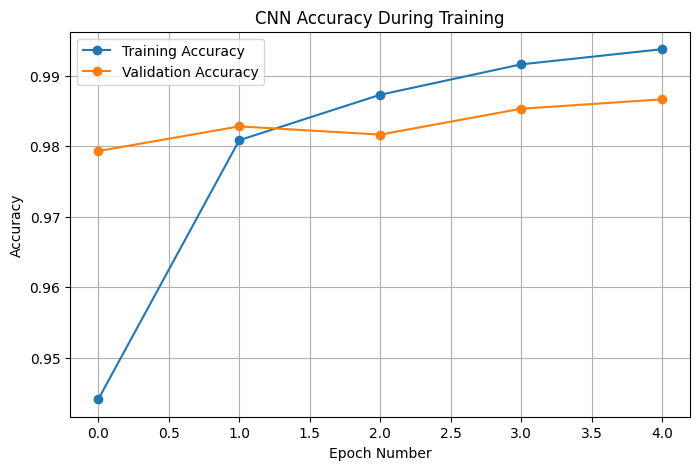

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    training_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    training_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("CNN Accuracy During Training")
plt.xlabel("Epoch Number")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


### Explanation

The accuracy graph illustrates how the model's classification performance changes across epochs.

Training accuracy represents performance on the training subset, while validation accuracy represents performance on the held-out validation subset. Comparing these curves helps assess whether the model is learning effectively.


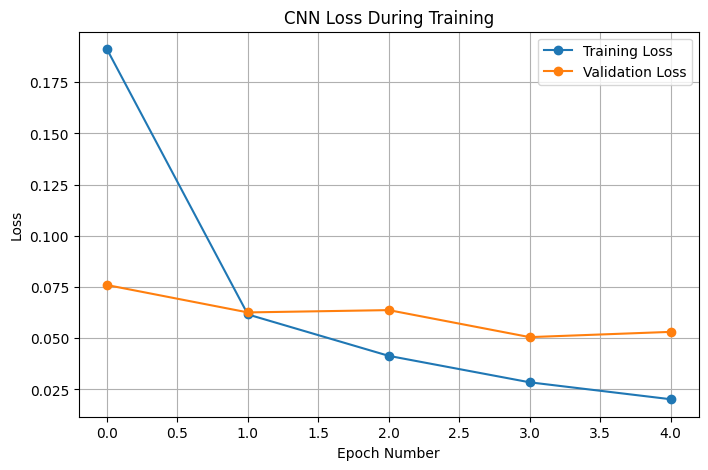

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    training_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    training_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("CNN Loss During Training")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


### Explanation

The loss graph shows how the model's prediction error changes over time. Lower loss generally indicates that the predictions are improving.

If training loss continues to decrease while validation loss rises, the model may be overfitting the training data.

### Result of Task 2

The CNN architecture was created and compiled successfully. The model was trained on the MNIST training data, and the training and validation curves were plotted to study its learning behavior.



## Task 3: Evaluate the Model

### Theory

After training, the CNN must be tested to determine how accurately it recognizes digits from unseen images.

This project uses four main evaluation methods:

- **Test accuracy:** Measures overall classification correctness.
- **Confusion matrix:** Identifies correct predictions and common classification errors.
- **Classification report:** Provides precision, recall, F1-score, and support for each class.
- **Sample predictions:** Visually compares predicted digits with their actual labels.


In [11]:
loss_value, accuracy_value = cnn_model.evaluate(
    test_images,
    test_labels,
    verbose=0
)

print(f"Testing loss: {loss_value:.4f}")
print(f"Testing accuracy: {accuracy_value * 100:.2f}%")

Testing loss: 0.0521
Testing accuracy: 98.23%



### Explanation

The test dataset is used to measure the model's ability to recognize images that were not included in its training process.

Test accuracy indicates the percentage of correctly predicted test images. Test loss provides an additional measure of prediction error.


In [12]:
probabilities = cnn_model.predict(test_images, verbose=0)

predicted_labels = np.argmax(probabilities, axis=1)

print("Actual digits:   ", test_labels[:10])
print("Predicted digits:", predicted_labels[:10])

Actual digits:    [7 2 1 0 4 1 4 9 5 9]
Predicted digits: [7 2 1 0 4 1 4 9 5 9]



### Explanation

The trained network produces a probability distribution across the ten digit classes for each input image.

The `argmax()` function selects the class with the highest probability. This class becomes the predicted digit, which can then be compared with the actual label.


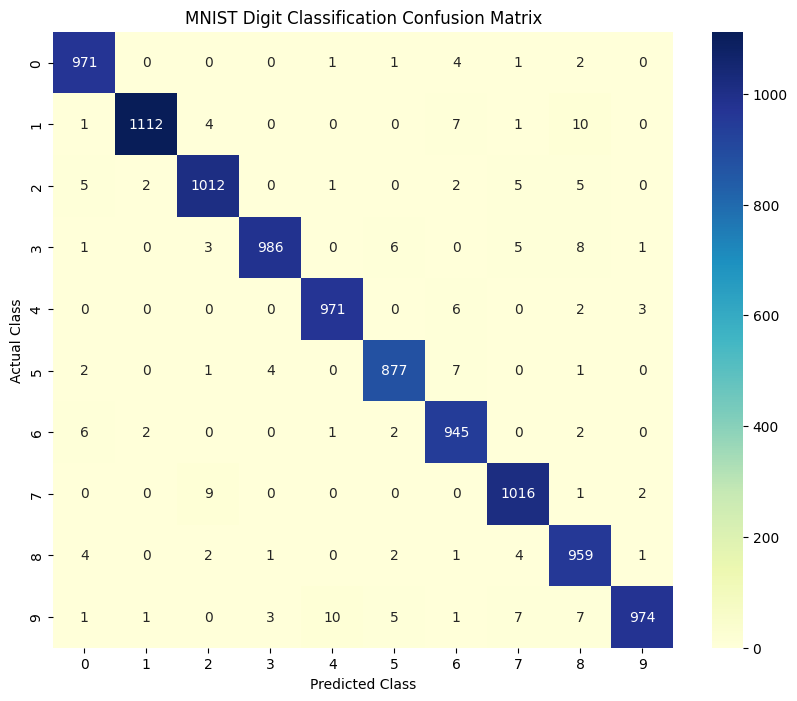

In [13]:
matrix = confusion_matrix(test_labels, predicted_labels)

plt.figure(figsize=(10, 8))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("MNIST Digit Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


### Explanation

The confusion matrix provides a class-by-class comparison of actual and predicted digits.

The main diagonal contains the correctly classified images. Values outside the diagonal represent mistakes, showing which digits have been confused with other digits.

A strong classification model generally has high counts along the diagonal and comparatively small counts elsewhere.


In [14]:
print("Detailed Classification Report:\n")

print(
    classification_report(
        test_labels,
        predicted_labels,
        labels=list(range(10)),
        target_names=[str(digit) for digit in range(10)],
        digits=4,
        zero_division=0
    )
)

Detailed Classification Report:

              precision    recall  f1-score   support

           0     0.9798    0.9908    0.9853       980
           1     0.9955    0.9797    0.9876      1135
           2     0.9816    0.9806    0.9811      1032
           3     0.9920    0.9762    0.9840      1010
           4     0.9868    0.9888    0.9878       982
           5     0.9821    0.9832    0.9826       892
           6     0.9712    0.9864    0.9788       958
           7     0.9779    0.9883    0.9831      1028
           8     0.9619    0.9846    0.9731       974
           9     0.9929    0.9653    0.9789      1009

    accuracy                         0.9823     10000
   macro avg     0.9822    0.9824    0.9822     10000
weighted avg     0.9824    0.9823    0.9823     10000




### Explanation

The classification report summarizes performance separately for every digit class.

- **Precision:** Measures how many predictions for a class are correct.
- **Recall:** Measures how many actual examples of a class are detected correctly.
- **F1-score:** Combines precision and recall into one metric.
- **Support:** Indicates the number of test examples belonging to each class.

Macro average treats all classes equally, while weighted average accounts for the number of examples in each class.


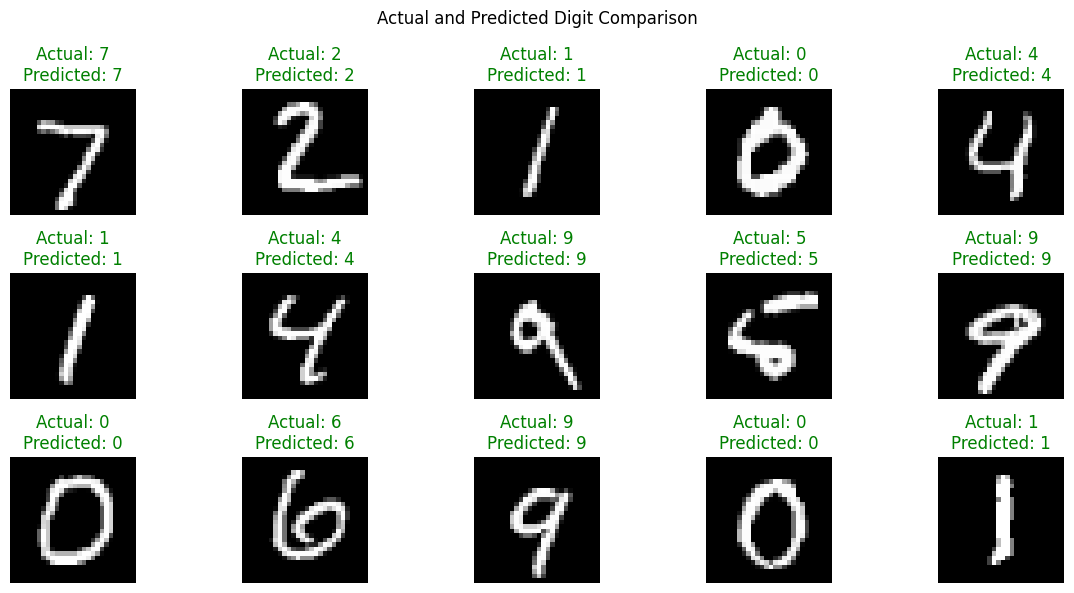

In [15]:
plt.figure(figsize=(12, 6))

for index in range(15):
    plt.subplot(3, 5, index + 1)

    plt.imshow(test_images[index].squeeze(), cmap="gray")

    actual_digit = test_labels[index]
    predicted_digit = predicted_labels[index]

    title_color = "green" if actual_digit == predicted_digit else "red"

    plt.title(
        f"Actual: {actual_digit}\nPredicted: {predicted_digit}",
        color=title_color
    )

    plt.axis("off")

plt.suptitle("Actual and Predicted Digit Comparison")
plt.tight_layout()
plt.show()


### Explanation

Fifteen test images are displayed alongside their actual and predicted digits.

Green labels indicate that the prediction matches the correct digit. Red labels indicate a classification error.

This visual comparison makes it easier to observe the model's successful predictions and identify examples that require further investigation.


In [16]:
errors_only = matrix.copy()
np.fill_diagonal(errors_only, 0)

actual_class, predicted_class = np.unravel_index(
    np.argmax(errors_only),
    errors_only.shape
)

print("Most common confusion:")
print(f"Actual digit: {actual_class}")
print(f"Predicted digit: {predicted_class}")
print(
    "Number of such errors:",
    matrix[actual_class, predicted_class]
)

Most common confusion:
Actual digit: 1
Predicted digit: 8
Number of such errors: 10



### Explanation

The diagonal entries of the confusion matrix represent correct predictions. They are set to zero in a copy of the matrix so that the largest remaining entry identifies the most frequent type of classification error.

This analysis helps determine which pair of digits the network confuses most often.

### Result of Task 3

The CNN was assessed using test accuracy, a confusion matrix, a classification report, and visual predictions. The results provide information about its overall performance and its ability to distinguish between different handwritten digits.



## Overall Result

The handwritten digit classification model was implemented using a Convolutional Neural Network and the MNIST dataset. Image preprocessing was completed before the network was trained.

The model learned visual features through convolution and pooling operations and used dense layers to predict the digit classes. Its performance was examined using test accuracy, a confusion matrix, classification metrics, and sample predictions.



## Conclusion

This project demonstrated the implementation of a CNN for recognizing handwritten numerical digits. The MNIST images were loaded, normalized, and reshaped into the appropriate input format.

The network was trained using the Adam optimizer and sparse categorical cross-entropy loss. Its classification performance was evaluated on a separate test dataset.

The confusion matrix revealed the distribution of correct predictions and classification errors, while the classification report summarized precision, recall, and F1-score for every digit. Sample predictions provided a visual understanding of the model's behavior.

Overall, the project illustrates how deep learning and convolutional layers can be applied to handwritten digit recognition.
